# Evidence for the dashboard's claims

Every backtest number the dashboard shows — the rank ICs beside each factor and strategy, the ordering of the quintiles, and the decision to show percentiles rather than forecast returns — is re-derived here from one frozen file, on two samples:

| Sample | Rebalance dates | Role |
|---|---|---|
| **Development** | Mar 2023 – Jan 2025 (23 month-ends) | Every design choice was made on these dates (`backtest.ipynb`) |
| **Embargo** | Feb – Apr 2025 | Skipped, so no return window overlaps both samples |
| **Holdout** | May 2025 – Oct 2026 | Untouched until the specification was frozen (`warehouse.spec`, 23 Nov 2026). Run once, here, and reported whatever it shows |

**Input.** `backtest/output/model_data.parquet`, written by the last cell of `backtest.ipynb`: one row per (month-end, stock) with each signal and the stock's forward returns. Nothing in this notebook re-fits or re-chooses anything; it only measures.

**Target.** The next month's *factor-adjusted* return: the stock's excess return minus what its Fama–French five-factor betas predicted from the factors' realised returns that month. A signal that only loads on known factors scores zero.

**Statistics.**
- *Rank IC*: the Spearman correlation, across stocks on one date, between the signal and the target. Its mean over dates is the signal's strength; the Fama–MacBeth *t*-stat (mean ÷ standard error of the monthly series) is how sure we can be it isn't zero.
- *Q5 − Q1*: the equal-weight mean target of the top signal quintile minus the bottom, per month.
- A *t* of 2 is the conventional bar; Harvey, Liu & Zhu (2016) argue for 3 once many signals have been tried.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

data = pd.read_parquet('../backtest/output/model_data.parquet')
data['rebalance_date'] = pd.to_datetime(data['rebalance_date'])
data = data[data['rebalance_date'] >= '2023-03-01']  # coverage is too thin before (backtests.md §4)

TARGET = 'fwd_adj_1m'
MIN_STOCKS = 30  # a date with fewer stocks holding the signal is skipped (same rule as backtest.ipynb)
SAMPLES = {'Development': data['split'].eq('development'), 'Holdout': data['split'].eq('holdout')}

# The signals as the screener shows them. Value is the equal-weight average of the four kept
# reverse-DCF alphas (CAPM benchmark); a composite is the mean of its factors' within-date
# percentiles, missing if any factor is missing — the same arithmetic as lib/screen.ts.
SIGNALS = {
    'Value + momentum composite': 'value_momentum',
    'Momentum + earnings surprise': 'momentum_surprise',
    'Value (implied excess return)': 'alpha_combined',
    'Momentum (12–1)': 'momentum',
    'Earnings surprise': 'surprise',
}
SCREENER_IDS = {'value_momentum': 'composite:momentum+value', 'momentum_surprise': 'composite:momentum+surprise',
                'alpha_combined': 'value', 'momentum': 'momentum', 'surprise': 'surprise'}

# Mid-tone colours that read on the site's dark and light surfaces; transparent figures.
COLOURS = dict(zip(SIGNALS, ['#6f93e8', '#c9a45a', '#0ea48c', '#9b7fd4', '#d6683c']))
plt.rcParams.update({'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none',
                     'text.color': '#8a8378', 'axes.labelcolor': '#8a8378', 'xtick.color': '#8a8378',
                     'ytick.color': '#8a8378', 'axes.edgecolor': '#8a8378', 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})

data.groupby('split')['rebalance_date'].agg(['min', 'max', 'nunique'])

,min,max,nunique
split,,,
development,2023-03-31,2025-01-31,23
embargo,2025-02-28,2025-04-30,3
holdout,2025-05-30,2026-10-30,18


In [2]:
def date_stats(d, col):
    """Rank IC, quintile means and the top-minus-bottom spread on one rebalance date."""
    s = d[[col, TARGET]].dropna()
    if len(s) < MIN_STOCKS:
        return None
    q = pd.qcut(s[col].rank(method='first'), 5, labels=range(1, 6))
    means = s.groupby(q, observed=True)[TARGET].mean()
    return {'ic': s[col].corr(s[TARGET], method='spearman'), 'spread': means[5] - means[1],
            'coverage': len(s) / len(d), **{f'q{k}': v for k, v in means.items()}}

def t_stat(x):
    """Fama–MacBeth t: mean of the monthly series over its standard error (1m windows don't overlap)."""
    x = x.dropna()
    return x.mean() / (x.std(ddof=1) / np.sqrt(len(x)))

tested = data[data[TARGET].notna()]
by_date = pd.DataFrame([{'signal': name, 'sample': d['split'].iat[0], 'rebalance_date': date, **stats}
                        for name, col in SIGNALS.items()
                        for date, d in tested.groupby('rebalance_date')
                        if d['split'].iat[0] in ('development', 'holdout') and (stats := date_stats(d, col))])
by_date['sample'] = by_date['sample'].str.capitalize()

g = by_date.groupby(['signal', 'sample'], sort=False)
summary = pd.DataFrame({
    'mean IC': g['ic'].mean(),
    'IC t-stat': g['ic'].apply(t_stat),
    'share of months IC > 0': g['ic'].apply(lambda x: (x > 0).mean()),
    'Q5 − Q1 per month': g['spread'].mean(),
    'spread t-stat': g['spread'].apply(t_stat),
    'coverage': g['coverage'].mean(),
    'months': g['ic'].count(),
})
summary.round(3)

mean IC  IC t-stat  \
signal                        sample                            
Value + momentum composite    Development    0.054      1.916   
                              Holdout        0.033      1.037   
Momentum + earnings surprise  Development    0.035      1.468   
                              Holdout        0.057      2.011   
Value (implied excess return) Development    0.032      1.179   
                              Holdout        0.023      0.612   
Momentum (12–1)               Development    0.029      1.183   
                              Holdout        0.014      0.301   
Earnings surprise             Development    0.024      1.452   
                              Holdout        0.066      3.306   

                                           share of months IC > 0  \
signal                        sample                                
Value + momentum composite    Development                   0.696   
                              Holdout                       0.625   
Momentum + earnings surprise  Development                   0.696   
                              Holdout                       0.750   
Value (implied excess return) Development                   0.565   
                              Holdout                       0.625   
Momentum (12–1)               Development                   0.652   
                              Holdout                       0.500   
Earnings surprise             Development                   0.565   
                              Holdout                       0.750   

                                           Q5 − Q1 per month  spread t-stat  \
signal                        sample                                          
Value + momentum composite    Development              0.008          1.382   
                              Holdout                  0.003          0.477   
Momentum + earnings surprise  Development              0.008          1.566   
                              Holdout                  0.018          2.325   
Value (implied excess return) Development              0.003          0.472   
                              Holdout                 -0.003         -0.358   
Momentum (12–1)               Development              0.005          0.854   
                              Holdout                  0.011          0.873   
Earnings surprise             Development              0.002          0.593   
                              Holdout                  0.016          2.668   

                                           coverage  months  
signal                        sample                         
Value + momentum composite    Development     0.977      23  
                              Holdout         0.972      16  
Momentum + earnings surprise  Development     0.987      23  
                              Holdout         0.991      16  
Value (implied excess return) Development     0.979      23  
                              Holdout         0.974      16  
Momentum (12–1)               Development     0.998      23  
                              Holdout         0.999      16  
Earnings surprise             Development     0.989      23  
                              Holdout         0.992      16

**Reading the table.** The development rows reproduce the numbers the screener prints beside each factor and strategy (value 0.032, *t* = 1.18; value + momentum 0.054, *t* = 1.92; momentum + surprise 0.035, *t* = 1.47). The holdout has 16 months with an outcome: the factor-adjusted target needs Kenneth French's factor returns, which lag the price data.

**Holdout result.**
- **Value + momentum composite** (the screener's default strategy): mean IC 0.033, *t* = 1.04, positive in 63% of months. Same sign as development, about 60% of its strength, and not significant. Its Q5 − Q1 spread (+0.3% a month, *t* = 0.48) is not distinguishable from zero.
- **Momentum + earnings surprise**: mean IC 0.057, *t* = 2.01, positive in 75% of months, Q5 − Q1 +1.8% a month (*t* = 2.33). The only strategy above the conventional *t* = 2 bar out of sample, though below Harvey–Liu–Zhu's 3.
- **Earnings surprise alone**: mean IC 0.066, *t* = 3.31: the strongest single factor in the holdout, and the only one above 3.
- **Value alone**: mean IC 0.023, *t* = 0.61. The ordering is right on average, but its extreme quintiles do not separate (Q5 − Q1 −0.3% a month).
- **Momentum alone**: mean IC 0.014, *t* = 0.30.

**What this does and does not show.** The holdout tests the specification frozen before it was run; it does not pick a new one. Switching the default strategy because momentum + surprise did better here would turn the holdout into a second development sample, and the next out-of-sample test would have to wait for new months. The site therefore keeps value + momentum as its default and prints both samples beside every strategy.

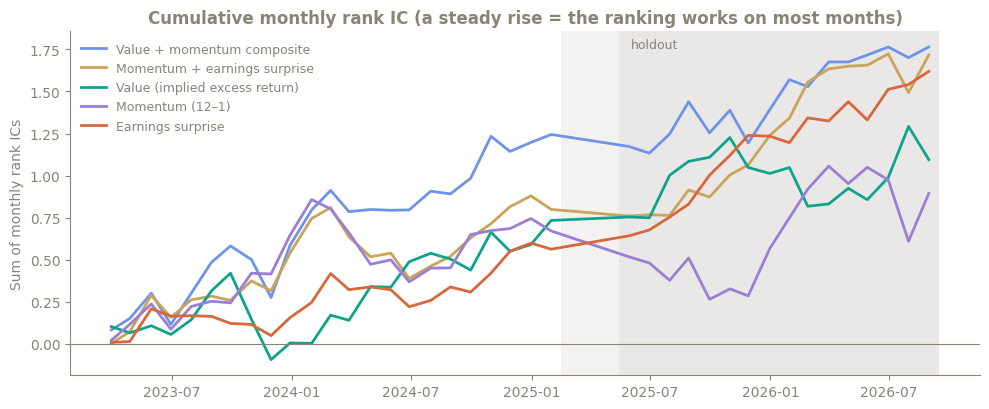

In [3]:
def shade(ax):
    """Mark the embargo and holdout on a time axis."""
    ax.axvspan(pd.Timestamp('2025-02-15'), pd.Timestamp('2025-05-15'), color='#8a8378', alpha=0.10, lw=0)
    ax.axvspan(pd.Timestamp('2025-05-15'), by_date['rebalance_date'].max() + pd.Timedelta(days=15), color='#8a8378', alpha=0.18, lw=0)
    ax.text(pd.Timestamp('2025-06-01'), 0.98, 'holdout', transform=ax.get_xaxis_transform(), va='top', fontsize=9)

fig, ax = plt.subplots(figsize=(10, 4.2))
for name, d in by_date.groupby('signal', sort=False):
    ax.plot(d['rebalance_date'], d['ic'].cumsum(), lw=2, color=COLOURS[name], label=name)
ax.axhline(0, color='#8a8378', lw=0.8)
shade(ax)
ax.set_title('Cumulative monthly rank IC (a steady rise = the ranking works on most months)')
ax.set_ylabel('Sum of monthly rank ICs')
ax.legend(frameon=False, fontsize=9, loc='upper left')
fig.tight_layout()
plt.show()

**Figure 1.** A signal that ranks stocks well rises steadily; one that works only in some months climbs in steps and gives some back. In the holdout (shaded), both composites keep rising, momentum + surprise faster. Momentum alone loses ground until late 2025, then recovers, and value alone gains until late 2025 and then gives it back. The line runs straight across the three skipped embargo months.

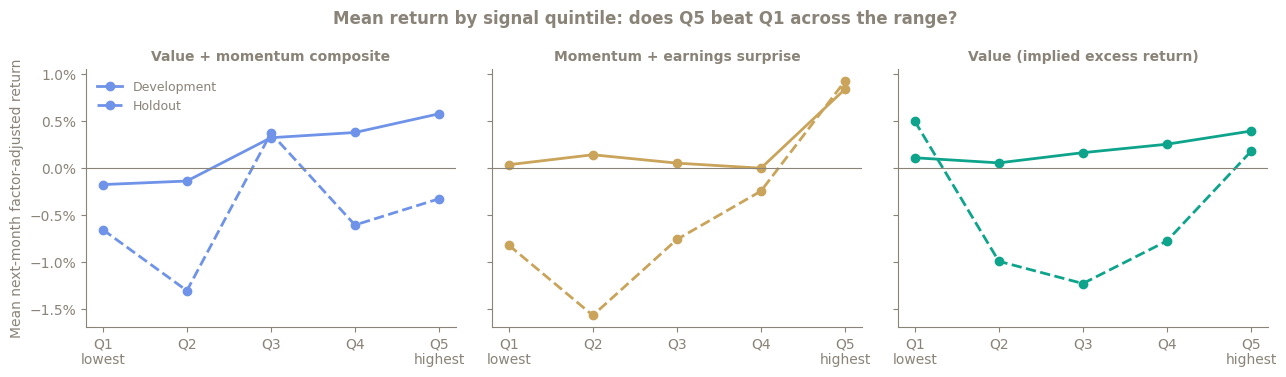

In [4]:
quintiles = by_date.groupby(['signal', 'sample'], sort=False)[[f'q{k}' for k in range(1, 6)]].mean()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, name in zip(axes, list(SIGNALS)[:3]):
    for sample, style in [('Development', '-'), ('Holdout', '--')]:
        ax.plot(range(1, 6), quintiles.loc[(name, sample)].values, style, marker='o', lw=2, color=COLOURS[name], label=sample)
    ax.axhline(0, color='#8a8378', lw=0.8)
    ax.set_xticks(range(1, 6), ['Q1\nlowest', 'Q2', 'Q3', 'Q4', 'Q5\nhighest'])
    ax.set_title(name, fontsize=10)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
axes[0].set_ylabel('Mean next-month factor-adjusted return')
axes[0].legend(frameon=False, fontsize=9)
fig.suptitle('Mean return by signal quintile: does Q5 beat Q1 across the range?', color='#8a8378', fontweight='bold')
fig.tight_layout()
plt.show()

**Figure 2.** The screener's quintile chips (Q5 · highest … Q1 · lowest) are only meaningful if returns rise from Q1 to Q5. In development all three rise, if gently. In the holdout only momentum + surprise is close to monotone (from Q2 up); value + momentum peaks in Q3, and value alone is U-shaped, its cheapest and dearest quintiles both beating the middle.

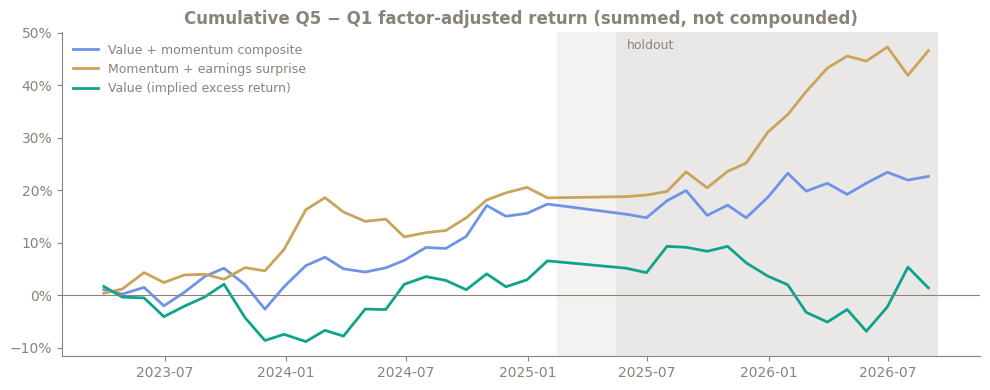

In [5]:
spreads = by_date.pivot_table(index='rebalance_date', columns='signal', values='spread')[list(SIGNALS)]
fig, ax = plt.subplots(figsize=(10, 4))
for name in list(SIGNALS)[:3]:
    ax.plot(spreads.index, spreads[name].cumsum(), lw=2, color=COLOURS[name], label=name)
ax.axhline(0, color='#8a8378', lw=0.8)
shade(ax)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_title('Cumulative Q5 − Q1 factor-adjusted return (summed, not compounded)')
ax.legend(frameon=False, fontsize=9, loc='upper left')
fig.tight_layout()
plt.show()

**Figure 3.** Factor-adjusted returns are not a tradable portfolio (they subtract each stock's own factor exposure), so the monthly spreads are summed rather than compounded. The figure shows how much return each signal separated beyond the five factors, month by month.

### Why the site shows percentiles, not forecast returns

The value factor starts from an *implied excess return* in percentage points a year. If that number were a forecast, stocks predicted to beat their required return by 10 pp should, on average, have done so. Within each month, stocks are sorted into deciles of predicted alpha (clipped at the 1st/99th percentile); each decile's mean prediction is plotted against its mean realised factor-adjusted return (1-month × 12). The per-month slope of realised on predicted is 1 for a calibrated forecast.

,slope,slope t-stat,months
Development,0.168,0.299,23.0
Holdout,-0.443,-0.513,16.0


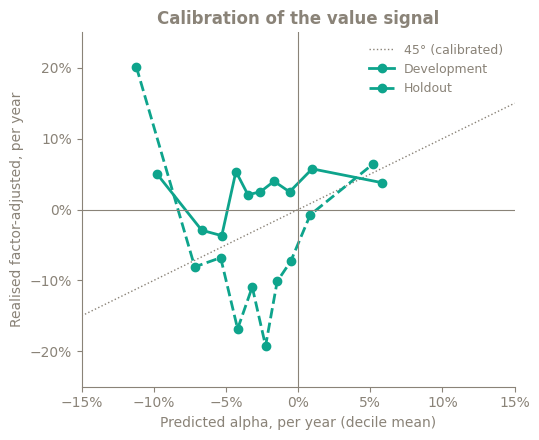

In [6]:
def calibration(sample):
    d = data.loc[SAMPLES[sample] & data[TARGET].notna() & data['alpha_combined'].notna(),
                 ['rebalance_date', 'alpha_combined', TARGET]].copy()
    d['realised'] = 12 * d[TARGET]
    by = d.groupby('rebalance_date')['alpha_combined']
    d['predicted'] = d['alpha_combined'].clip(by.transform(lambda x: x.quantile(0.01)), by.transform(lambda x: x.quantile(0.99)))
    d['decile'] = by.transform(lambda x: pd.qcut(x.rank(method='first'), 10, labels=False)) + 1
    slopes = d.groupby('rebalance_date').apply(lambda x: np.polyfit(x['predicted'], x['realised'], 1)[0], include_groups=False)
    return d.groupby('decile')[['predicted', 'realised']].mean(), slopes

calib = {s: calibration(s) for s in SAMPLES}
display(pd.DataFrame({s: {'slope': sl.mean(), 'slope t-stat': t_stat(sl), 'months': len(sl)} for s, (_, sl) in calib.items()}).T.round(3))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
lim = [-0.15, 0.15]
ax.plot(lim, lim, color='#8a8378', lw=1, ls=':', label='45° (calibrated)')
for sample, style in [('Development', '-'), ('Holdout', '--')]:
    dec = calib[sample][0]
    ax.plot(dec['predicted'], dec['realised'], style, marker='o', lw=2, color=COLOURS['Value (implied excess return)'], label=sample)
ax.axhline(0, color='#8a8378', lw=0.8); ax.axvline(0, color='#8a8378', lw=0.8)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel('Predicted alpha, per year (decile mean)'); ax.set_ylabel('Realised factor-adjusted, per year')
ax.set_title('Calibration of the value signal')
ax.set_xlim(lim); ax.set_ylim(-0.25, 0.25)
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

**Figure 4.** The development slope is 0.17 (*t* = 0.30) and the holdout slope −0.44 (*t* = −0.51): neither is distinguishable from zero, and both are far from 1. A stock's *rank* on implied excess return carries some information, but its *size* in pp is not a return forecast. That is why the screener converts every factor to a percentile and colours the implied excess return by quintile rather than presenting it as expected alpha.

### Not tested here
- **Graham defensive (partial).** Graham's screen needs 10 years of uninterrupted dividends and 20 of earnings; the data holds 4 years of statements, so the strategy is shown as a rule-based screen without an IC.
- **The four reverse-DCF models separately, the growth assumption and the required-return benchmark** are development-period tests in `backtest.ipynb`; they chose the specification, so re-running them on the holdout would not change what the site shows.

### Development-sample tests the Methodology page quotes

Two results from `backtest.ipynb` are re-derived here so the site can read them from the same file as every other figure: each reverse-DCF model against the plain ratio it is built from (scored on the same stocks, with the difference in monthly ICs getting its own *t*-stat), and the value signal's top-minus-bottom-quintile return on raw returns, then regressed on the five Fama–French factors. Both use the development months only, as in the original notebook.

In [7]:
def monthly_ic(df, col):
    """Monthly rank IC of one signal against the factor-adjusted target (same date rule as above)."""
    out = {}
    for date, d in df.groupby('rebalance_date'):
        s = d[[col, TARGET]].dropna()
        if len(s) >= MIN_STOCKS:
            out[date] = s[col].corr(s[TARGET], method='spearman')
    return pd.Series(out)

dev = data[SAMPLES['Development'] & data[TARGET].notna()]
PAIRS = [('FCFF', 'alpha_fcff', 'FCF yield', 'fcf_yield'),
         ('Residual income', 'alpha_rim', 'Book-to-price', 'book_to_price'),
         ('Residual income', 'alpha_rim', 'Earnings yield', 'earnings_yield'),
         ('Revenue', 'alpha_rev', 'Sales-to-EV', 'sales_to_ev'),
         ('Shareholder yield', 'alpha_shy', 'Payout ÷ market cap', 'shy_ratio')]
model_vs_ratio = []
for model, mcol, ratio, rcol in PAIRS:
    both = dev[dev[mcol].notna() & dev[rcol].notna()]  # the same stocks for both
    m, rt = monthly_ic(both, mcol), monthly_ic(both, rcol)
    diff = m - rt
    model_vs_ratio.append({'model': model, 'ratio': ratio, 'modelIc': m.mean(), 'ratioIc': rt.mean(),
                           't': t_stat(diff), 'wins': (diff > 0).mean()})
model_vs_ratio.append({'model': 'All four, averaged', 'ratio': 'Plain-ratio composite',
                       'modelIc': monthly_ic(dev, 'alpha_combined').mean(),
                       'ratioIc': monthly_ic(dev, 'ratio_composite').mean(), 't': None, 'wins': None})

# Value signal, top fifth minus bottom fifth, equal weight, raw next-month returns.
FACTORS = ['mkt', 'smb', 'hml', 'rmw', 'cma']
ls_rows = data[SAMPLES['Development'] & data['fwd_return_1m'].notna() & data['alpha_combined'].notna()]
ls_rows = ls_rows[ls_rows.groupby('rebalance_date')['alpha_combined'].transform('count') >= MIN_STOCKS]
quint = ls_rows.groupby('rebalance_date')['alpha_combined'].transform(lambda x: pd.qcut(x.rank(method='first'), 5, labels=False))
leg = lambda k: ls_rows[quint == k].groupby('rebalance_date')['fwd_return_1m'].mean()
long_short = leg(4) - leg(0)
factor_returns = data[SAMPLES['Development']].groupby('rebalance_date')[[f'fwd_{f}_1m' for f in FACTORS]].first()
y, X = long_short.to_numpy(), factor_returns.loc[long_short.index].to_numpy()
A = np.column_stack([np.ones(len(X)), X])
coef, *_ = np.linalg.lstsq(A, y, rcond=None)
resid = y - A @ coef
se = np.sqrt(np.diag(np.linalg.inv(A.T @ A)) * (resid @ resid) / (len(y) - A.shape[1]))
value_attribution = {'longShort': long_short.mean(), 'alpha': 12 * coef[0], 'alphaT': coef[0] / se[0], 'months': len(long_short)}

pd.DataFrame(model_vs_ratio).round(3), {k: round(float(v), 3) for k, v in value_attribution.items()}

(                model                  ratio  modelIc  ratioIc      t   wins
 0                FCFF              FCF yield    0.034    0.015  0.998  0.522
 1     Residual income          Book-to-price    0.021    0.005  0.858  0.478
 2     Residual income         Earnings yield    0.021   -0.002  1.567  0.652
 3             Revenue            Sales-to-EV    0.029    0.024  0.230  0.391
 4   Shareholder yield    Payout ÷ market cap    0.043    0.024  0.902  0.478
 5  All four, averaged  Plain-ratio composite    0.032    0.012    NaN    NaN,
 {'longShort': -0.007, 'alpha': -0.043, 'alphaT': -0.76, 'months': 23.0})

In [8]:
# Export for the site: app/research/_data/evidence.json. The research page and the
# factor/strategy labels read their numbers from this file, so re-running this notebook
# is the only way a backtest figure on the site changes.
def r(x, n=4):
    return None if pd.isna(x) else round(float(x), n)

out = {
    'generated': pd.Timestamp.now().strftime('%Y-%m-%d'),
    'target': 'Next-month Fama–French five-factor-adjusted return',
    'samples': {s: {'first': by_date.loc[by_date['sample'] == s, 'rebalance_date'].min().strftime('%Y-%m'),
                    'last': by_date.loc[by_date['sample'] == s, 'rebalance_date'].max().strftime('%Y-%m')} for s in SAMPLES},
    'signals': [{
        'id': SCREENER_IDS[col], 'label': name,
        **{s.lower(): {k: r(summary.loc[(name, s), c]) for k, c in [('ic', 'mean IC'), ('t', 'IC t-stat'),
                       ('hit', 'share of months IC > 0'), ('spread', 'Q5 − Q1 per month'), ('spreadT', 'spread t-stat'),
                       ('coverage', 'coverage'), ('months', 'months')]}
           | {'quintiles': [r(v, 5) for v in quintiles.loc[(name, s)].values]} for s in SAMPLES},
    } for name, col in SIGNALS.items()],
    'monthly': [{'date': date.strftime('%Y-%m'), 'sample': grp['sample'].iat[0],
                 **{SCREENER_IDS[SIGNALS[row.signal]]: {'ic': r(row.ic), 'spread': r(row.spread, 5)} for row in grp.itertuples()}}
                for date, grp in by_date.groupby('rebalance_date')],
    'calibration': {s.lower(): {'slope': r(sl.mean(), 3), 't': r(t_stat(sl), 2),
                                'deciles': [[r(p), r(q)] for p, q in dec[['predicted', 'realised']].itertuples(index=False)]}
                    for s, (dec, sl) in calib.items()},
    'modelVsRatio': [{k: (v if isinstance(v, str) else r(v)) for k, v in row.items()} for row in model_vs_ratio],
    'valueAttribution': {k: r(v) for k, v in value_attribution.items()},
}
path = Path('../../app/research/_data/evidence.json')
path.parent.mkdir(parents=True, exist_ok=True)
path.write_text(json.dumps(out, ensure_ascii=False, separators=(',', ':')))
print(path.resolve().relative_to(Path('../..').resolve()), f'{path.stat().st_size / 1024:.1f} KB')

app/research/_data/evidence.json 14.2 KB
